In [1]:
import pandas as pd
import numpy as np
!pip install geopy
from geopy.distance import geodesic
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score
from sklearn.model_selection import GridSearchCV
import xgboost as xg
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
delivery_data = pd.read_csv('/content/drive/MyDrive/Zomato Dataset.csv/Zomato Dataset.csv')

In [4]:
delivery_data

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45579,0x7c09,JAPRES04DEL01,30.0,4.8,26.902328,75.794257,26.912328,75.804257,24-03-2022,11:35,11:45,Windy,High,1,Meal,motorcycle,0.0,No,Metropolitian,32
45580,0xd641,AGRRES16DEL01,21.0,4.6,0.000000,0.000000,0.070000,0.070000,16-02-2022,19:55,20:10,Windy,Jam,0,Buffet,motorcycle,1.0,No,Metropolitian,36
45581,0x4f8d,CHENRES08DEL03,30.0,4.9,13.022394,80.242439,13.052394,80.272439,11-03-2022,23:50,24:05:00,Cloudy,Low,1,Drinks,scooter,0.0,No,Metropolitian,16
45582,0x5eee,COIMBRES11DEL01,20.0,4.7,11.001753,76.986241,11.041753,77.026241,07-03-2022,13:35,13:40,Cloudy,High,0,Snack,motorcycle,1.0,No,Metropolitian,26


In [5]:
delivery_data.isnull().sum()

,0
ID,0
Delivery_person_ID,0
Delivery_person_Age,1854
Delivery_person_Ratings,1908
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,1731


In [6]:
delivery_data['Type_of_vehicle'].value_counts()

,count
Type_of_vehicle,
motorcycle,26429
scooter,15273
electric_scooter,3814
bicycle,68


In [7]:
delivery_data.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken (min)
count,43730.000000,43676.000000,45584.000000,45584.000000,45584.000000,45584.000000,45584.000000,44591.000000,45584.000000
mean,29.566911,4.633774,17.017948,70.229684,17.465480,70.844161,1.023385,0.744635,26.293963
std,5.815064,0.334744,8.185674,22.885575,7.335562,21.120578,0.839055,0.572510,9.384298
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.551440,75.897963,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


Here Delivery Person are repeating as IDs are lesser than records so we fill where age and ratings values are missing use the previous entries for similar IDs . But we check that no two IDs are similar or IDs are repeating with different age because then that means its different person or there is some error in the data. In the rating we take average of all ratings given to that delivery person ID.

In [8]:
age_check = (
    delivery_data.groupby('Delivery_person_ID')['Delivery_person_Age']
      .nunique()
      .sort_values(ascending=False)
)

age_check.head()

,Delivery_person_Age
Delivery_person_ID,
BANGRES05DEL01,22
COIMBRES07DEL01,21
RANCHIRES06DEL02,21
BANGRES16DEL02,21
COIMBRES17DEL02,21


In [9]:
delivery_data['Delivery_person_Age'] = (
    delivery_data['Delivery_person_Age']
      .fillna(
          delivery_data.groupby('Delivery_person_ID')['Delivery_person_Age']
            .transform('first')
      )
)

In [10]:
delivery_data['Delivery_person_Ratings'] = (
    delivery_data['Delivery_person_Ratings']
      .fillna(
          delivery_data.groupby('Delivery_person_ID')['Delivery_person_Ratings']
            .transform('mean')
      )
      .fillna(delivery_data['Delivery_person_Ratings'].mean())
)

In [11]:
delivery_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          45584 non-null  float64
 3   Delivery_person_Ratings      45584 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  object 
 9   Time_Orderd                  43853 non-null  object 
 10  Time_Order_picked            45584 non-null  object 
 11  Weather_conditions           44968 non-null  object 
 12  Road_traffic_density         44983 non-null  object 
 13  Vehicle_conditio

Now we want to fix Time_ordered missing values but first we convert the datatype from object to datetime we then see that there are missing values in both time_ordered and time_order_picked as there are some error values also like 0.1, 0.2 etc.

So now we check where both time_ordered and time_order_picked are null and delete those values.

for other null values (I have taken avg. time difference between both is 15 mins):
- if time_ordered value is missing subtract 15 mins from time_oder_picked
- if time_order_picked value is missing add 15 mins to time_ordered

then we convert these values again into just time (remove the date by converting from datetime to time)

In [12]:
delivery_data['Time_Orderd'] = pd.to_datetime(
    delivery_data['Time_Orderd'].astype(str).str.strip(),
    format='mixed',
    errors='coerce'
)

delivery_data['Time_Order_picked'] = pd.to_datetime(
    delivery_data['Time_Order_picked'].astype(str).str.strip(),
    format='mixed',
    errors='coerce'
)

In [13]:
delivery_data = delivery_data.dropna(
    subset=['Time_Orderd', 'Time_Order_picked'],
    how='all'
)

In [14]:
delivery_data['Time_Orderd'] = delivery_data['Time_Orderd'].fillna(
    delivery_data['Time_Order_picked'] - pd.Timedelta(minutes=15)
)

/tmp/ipykernel_997/595133637.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivery_data['Time_Orderd'] = delivery_data['Time_Orderd'].fillna(


In [15]:
delivery_data['Time_Order_picked'] = delivery_data['Time_Order_picked'].fillna(
    delivery_data['Time_Orderd'] + pd.Timedelta(minutes=15)
)

/tmp/ipykernel_997/744994479.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivery_data['Time_Order_picked'] = delivery_data['Time_Order_picked'].fillna(


In [16]:
delivery_data['Time_Orderd']=delivery_data['Time_Orderd'].dt.time
delivery_data['Time_Order_picked']=delivery_data['Time_Order_picked'].dt.time

/tmp/ipykernel_997/4366376.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivery_data['Time_Orderd']=delivery_data['Time_Orderd'].dt.time
/tmp/ipykernel_997/4366376.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivery_data['Time_Order_picked']=delivery_data['Time_Order_picked'].dt.time


Here we calculate the distance between restaurant and delivery location in km. and we put result in distance_km column.

In [17]:

# Apply geopy's geodesic function row-by-row
delivery_data['distance_km'] = delivery_data.apply(
    lambda row: geodesic((row['Restaurant_latitude'], row['Restaurant_longitude']), (row['Delivery_location_latitude'], row['Delivery_location_longitude'])).km,
    axis=1
)


/tmp/ipykernel_997/3612574222.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivery_data['distance_km'] = delivery_data.apply(


In [18]:
delivery_data['distance_km'] = delivery_data['distance_km'].round(2)

/tmp/ipykernel_997/4213763206.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  delivery_data['distance_km'] = delivery_data['distance_km'].round(2)


Now we plot the time_taken vs. distance_km graph . Now we know that no vehicle can cover 5000 km to 20,000 km in 1hour so we delete all points where distance is above 150 km. as there is some error in the data for sure.

In [19]:
fig = px.scatter(delivery_data, x="distance_km", y="Time_taken (min)", color="Road_traffic_density")
fig.show()

In [20]:
(delivery_data['distance_km']>150).sum()

np.int64(394)

In [21]:
delivery_data = delivery_data.drop(delivery_data[delivery_data['distance_km'] > 150].index)

In [22]:
delivery_data['City'].value_counts()

,count
City,
Metropolitian,33354
Urban,9884
Semi-Urban,162


In [23]:
delivery_data['City']=delivery_data['City'].fillna('Metropolitian')

In [24]:
delivery_data['Festival'].value_counts()

,count
Festival,
No,43457
Yes,880


In [25]:
delivery_data['Festival']=delivery_data['Festival'].fillna('No')

In [26]:
delivery_data['Weather_conditions'].value_counts()

,count
Weather_conditions,
Fog,7509
Stormy,7439
Cloudy,7383
Sandstorms,7361
Windy,7297
Sunny,7146


In [27]:
delivery_data['Weather_conditions']=delivery_data['Weather_conditions'].fillna('Fog')

In [28]:
delivery_data['multiple_deliveries'].value_counts()

,count
multiple_deliveries,
1.0,27505
0.0,13770
2.0,1958
3.0,357


In [29]:
delivery_data['multiple_deliveries']=delivery_data['multiple_deliveries'].fillna(1.0)

In [30]:
delivery_data.duplicated().sum()

np.int64(0)

In [31]:
delivery_data['Road_traffic_density'].value_counts()

,count
Road_traffic_density,
Low,14886
Jam,14008
Medium,10865
High,4387


In [32]:
delivery_data['Road_traffic_density']=delivery_data['Road_traffic_density'].fillna('Low')

Here we are droping the data where Restaurant latitude is 0.0 because it is a water body location so this data has errors and is not useful for our model.

In [33]:
delivery_data = delivery_data.drop(delivery_data[delivery_data['Restaurant_latitude'] == 0.0].index)

In [34]:
fig = px.scatter_mapbox( delivery_data,
    lat="Delivery_location_latitude",
    lon="Delivery_location_longitude", height=600)

fig.update_layout(mapbox_style="open-street-map")  # free tiles
fig.update_layout(title="Delivery Locations")
fig.update_layout(
    mapbox_center={"lat": 20.5937, "lon": 78.9629},
    mapbox_zoom=4.5
)
fig.show()

# My Clustering Approach

The main thing to understand is that **clustering is not about predicting `Time_taken`**. It is about discovering natural groups in delivery data.

Here we are building **two complementary clustering analyses**:

| Clustering                            | Algorithm | Purpose                                        |
| ------------------------------------- | --------- | ---------------------------------------------- |
| **Geographic Hotspot Clustering**     | HDBSCAN    | Find dense delivery zones/hotspots             |
| **Operational Delivery Segmentation** | K-Means   | Group orders into similar operational patterns |

Here we use HDBSCAN as the DBSCAN is not suitable for very large data .

This gives a much stronger project story:

> **“Where are the delivery hotspots, and what types of delivery operations occur in those areas?”**

---

## 1. First understand what clustering actually does

The algorithm discovers groups based on the variables given to it.

For example, after clustering you might discover:

**Cluster A**

* short distance
* low traffic
* low delivery time
* mostly single deliveries

**Cluster B**

* long distance
* high traffic
* multiple deliveries
* high delivery time

**Cluster C**

* medium distance
* moderate traffic
* good vehicle condition
* moderate delivery time

The algorithm creates the clusters.

**Give the clusters business meaning afterward.**

This distinction is extremely important.

---

## 2. Dataset has two different kinds of clustering opportunities

### Question A — Geography

> Where are orders geographically concentrated?

For this, use:

```text
Restaurant latitude
Restaurant longitude
Delivery latitude
Delivery longitude
```

This is where **HDBCAN** becomes very useful.

---

### Question B — Operational behavior

> What types of delivery orders have similar operating characteristics?

For this, use variables such as:

```text
Delivery distance
Order hour
Delivery person's rating
Age
Vehicle condition
Multiple deliveries
Weekday
```

This is where **K-Means** becomes useful.

---

## 3. Do NOT put these columns into clustering


| Column               | Use in clustering?        | Why                                    |
| -------------------- | ------------------------- | -------------------------------------- |
| `ID`                 | ❌ No                      | Just an identifier                     |
| `Delivery_person_ID` | ❌ No                      | Identifier, not behavior               |
| `Time_taken (min)`   | ❌ Generally no            | This is your outcome/target            |
| Raw `Order_Date`     | ❌ No                      | Transform into useful time features    |
| Raw time columns     | ❌ No                      | Engineer hour/delay                    |
| Coordinates          | ✅ Geo clustering          | Useful for geographic clusters         |
| Age                  | ✅ Operational clustering  | Rider characteristic                   |
| Rating               | ✅ Operational clustering  | Rider/order characteristic             |
| Vehicle_condition    | ✅ Operational clustering  | Operational characteristic             |
| multiple_deliveries  | ✅ Operational clustering  | Operational complexity                 |
| Weather              | ⚠️ Optional               | Better initially for cluster profiling |
| Traffic              | ⚠️ Optional               | Better initially for profiling         |
| Type_of_order        | ⚠️ Optional               | Categorical                            |
| Type_of_vehicle      | ⚠️ Optional               | Categorical                            |
| Festival             | ⚠️ Optional               | Can be used as profile                 |
| City                 | ⚠️ Usually profile/filter | Geography can dominate clusters        |

---

## 4. HDBSCAN for Geographical clustering

HDBSCAN looks for areas where points are **densely packed together**.

It can therefore find:

* delivery hotspots
* restaurant hotspots
* sparse areas
* geographically isolated orders

And importantly, DBSCAN can identify **noise/outliers**. K-Means cannot naturally do that.

We can make two clusters using HDBSCAN . First one is for delivery hotspots :

```text
Delivery_location_latitude
Delivery_location_longitude
```
And second for the restaurant locations :

```text
Restaurant_latitude
Restaurant_longitude
```

## 5. Why not to give HDBSCAN all four coordinates?


The business interpretation becomes messy.

The algorithm would be clustering **routes**, rather than simply geographical locations.


## 6. The two important DBSCAN parameters

DBSCAN mainly requires:

```text
eps
min_samples
```

These are extremely important.

---

### `eps`

`eps` means approximately:

> **How close should two points be to be considered neighbors?**

For example:

```text
eps = 500 metres
```

means:

> Consider nearby delivery locations within roughly 500 m as neighbors.

---

### `min_samples`

This means:

> How many neighboring points are necessary to call an area a dense cluster?

Suppose:

```text
min_samples = 30
```

HDBSCAN is saying:

> I need approximately 30 points within the neighborhood before treating this region as a dense area.

For DBSCAN, use the **Haversine distance** when working directly with latitude/longitude.

```text
Lower DB Index
        ↓
better separation
```


---

## 7. What should K-Means cluster?

For K-Means cluster we use this follwing :

```text
delivery_distance_km
order_hour
delivery_person_age
delivery_person_rating
vehicle_condition
Traffic
```


But we don't directly use `order_hour`  because :

Suppose:

```text
Order A = 23:00
Order B = 00:00
```

They are actually very close in time.

But mathematically:

```text
23 - 0 = 23
```

So K-Means may think they are very far apart.

This is why cyclical features are useful.

Create:

```text
hour_sin
hour_cos
```

Conceptually:

```text
hour
 ↓
sin(hour)
cos(hour)
```

Then:

```text
23:00 and 00:00
```

remain close to each other. think of a clock:

```text
             12
        11        1
      10            2
     9                3
      8              4
        7          5
             6
```

23:00 and 00:00 are neighbors on that circle.

This is a slightly more advanced feature-engineering concept, but it is very useful here.

---

## 8. Selecting number of clusters for K-Means

### Method 1 — Elbow Method

K-Means calculates something called:

### Inertia

Also called:

**Within-Cluster Sum of Squares (WCSS)**

It measures how close points are to their cluster center.

Generally:

```text
More clusters
      ↓
lower inertia
```

So you try:

```text
K = 2
K = 3
K = 4
K = 5
K = 6
K = 7
K = 8
```

and calculate inertia.

You might get:

```text
K    Inertia
2    5100
3    3700
4    2700
5    2300
6    2100
7    2000
8    1930
```

Plot:

```text
Inertia
 |
 |\
 | \
 |  \
 |    \
 |      \__
 |          \____
 +-----------------
   2  3  4  5  6
```

The point where improvement starts slowing is the **elbow**.

---

### Method - 2 Silhouette Score

Another important metric.

It basically asks:

> Is this point closer to its own cluster than to other clusters?

Range:

```text
-1 to +1
```

Conceptually:

```text
+1  → very well separated
 0  → overlapping clusters
-1  → potentially incorrectly grouped
```
This is much stronger than choosing K from one metric.

---

## 9. What insights we get from HDBSCAN geo clustering ?

Once we get our geo clusters using HDBSCAN, we profile all the clusters that is finding average distance in each cluster, number of orders, average time of delivery for a cluster etc.

| Cluster | Orders | Avg Distance | Avg Time | Avg Rating |
| ------- | -----: | -----------: | -------: | ---------: |
| 0       |  3,200 |       4.2 km |   26 min |        4.6 |            
| 1       |  2,100 |       7.8 km |   38 min |        4.4 |            
| 2       |  1,400 |       3.1 km |   21 min |        4.7 |

Now clustering actually becomes useful. We can draw meaningful insight like following :

> Cluster 1 represents a high-volume geographic delivery zone with longer average delivery distances and greater exposure to high traffic conditions.

## 10. What insight we get from K-Means operational clustering?

Once we get operational clusters using KMeans algo we need to profile these clusters based on traffic, multiple delivery, vehicle condition etc.

| Cluster | Orders | Avg Distance | Avg Time | Avg Rating | Avg Age | High Traffic % | Multiple Delivery % |
| ------- | -----: | -----------: | -------: | ---------: | ------: | -------------: | ------------------: |
| 0       | 15,420 |       3.2 km | 23.4 min |        4.7 |    30.8 |            18% |                  8% |
| 1       |  9,230 |       7.8 km | 38.2 min |        4.4 |    31.7 |            57% |                 42% |
| 2       | 12,800 |       5.1 km | 29.5 min |        4.6 |    31.1 |            35% |                 19% |
| 3       |  4,200 |       9.1 km | 43.7 min |        4.3 |    32.2 |            64% |                 51% |


---
## 11. Then combine the two

We combine both the clusters as shown in following table. We see each point is in which geo cluster and in which operational cluster then we draw insights from it.

For example:

| Order | Geo Cluster | Operational Cluster |
| ----- | ----------: | ------------------: |
| A     |           2 |                   1 |
| B     |           2 |                   0 |
| C     |           5 |                   1 |
| D     |           5 |                   3 |



Now we can draw insights like :

What operational patterns occur inside each geographic hotspot?
For example:

```text
Geo Cluster 5
       ↓
mostly Operational Cluster 3
       ↓
long distance
high traffic
multiple deliveries
       ↓
higher delivery time
```
That is an excellent business insight.

---

In [35]:
coords = delivery_data[['Delivery_location_latitude','Delivery_location_longitude']].values
coords = StandardScaler().fit_transform(coords)
hdb = HDBSCAN(min_cluster_size=400,
    min_samples=50,
    metric='haversine')
hdb.fit(coords)
delivery_data['hdb_delivery'] = hdb.labels_

In [36]:
delivery_data['hdb_delivery'].value_counts()

,count
hdb_delivery,
16,3379
5,3131
18,3127
0,3117
6,3107
11,3105
17,3093
1,3085
14,2514


In [37]:
fig = px.scatter_mapbox(
    delivery_data,
    lat="Delivery_location_latitude",
    lon="Delivery_location_longitude",
    color="hdb_delivery",
    height=600
)

fig.update_layout(mapbox_style="open-street-map")
fig.update_layout(title="Delivery Clusters ")
fig.update_layout(
    mapbox_center={"lat": 20.5937, "lon": 78.9629},
    mapbox_zoom=4.5
)
fig.show()

In [38]:
coords = delivery_data[['Restaurant_latitude','Restaurant_longitude']].values
coords = StandardScaler().fit_transform(coords)
hdb = HDBSCAN(min_cluster_size=400,
    min_samples=50,
    metric='haversine' )
hdb.fit(coords)
delivery_data['hdb_restaurant'] = hdb.labels_

In [39]:
delivery_data['hdb_restaurant'].nunique()

44

In [40]:
delivery_data['hdb_restaurant'].value_counts()

,count
hdb_restaurant,
-1,5979
3,3085
8,1409
15,1396
25,1392
23,1264
16,1245
24,1100
29,1098


In [41]:
fig = px.scatter_mapbox(
    delivery_data,
    lat="Restaurant_latitude",
    lon="Restaurant_longitude",
    color="hdb_restaurant",
    height=600
)

fig.update_layout(mapbox_style="open-street-map")
fig.update_layout(title="Restaurant Clusters ")
fig.update_layout(
    mapbox_center={"lat": 20.5937, "lon": 78.9629},
    mapbox_zoom=4.5
)
fig.show()

In [42]:
import datetime

delivery_data['Time_Orderd_Hour'] = delivery_data['Time_Orderd'].apply(
    lambda x: (
        x.hour
        if isinstance(x, datetime.time)
        else pd.to_datetime(x, errors='coerce').hour
        if pd.notna(x)
        else None
    )
)


In [43]:
delivery_data["hour_sin"] = np.sin(2 * np.pi * delivery_data["Time_Orderd_Hour"] / 24)
delivery_data["hour_cos"] = np.cos(2 * np.pi * delivery_data["Time_Orderd_Hour"] / 24)

In [44]:
encoder = LabelEncoder()
delivery_data['Traffic'] = encoder.fit_transform(delivery_data['Road_traffic_density'])
delivery_data['weather_num'] = encoder.fit_transform(delivery_data['Weather_conditions'])
delivery_data['order_num'] = encoder.fit_transform(delivery_data['Type_of_order'])
delivery_data['vehicle_num'] = encoder.fit_transform(delivery_data['Type_of_vehicle'])
delivery_data['fest_num'] = encoder.fit_transform(delivery_data['Festival'])
delivery_data['city_num'] = encoder.fit_transform(delivery_data['City'])

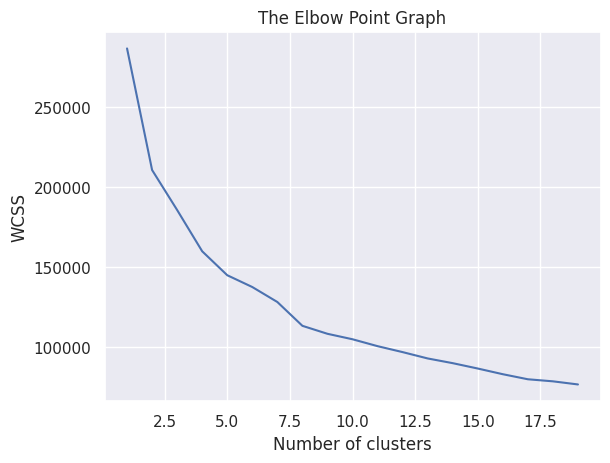

In [45]:
features = [
    'distance_km',
    'Delivery_person_Age',
    'Delivery_person_Ratings',
    'Vehicle_condition',
    'Traffic',
    'hour_sin',
    'hour_cos'
]

X = delivery_data[features].copy()

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

WCSS = []

for i in range(1,20):
    kmeans=KMeans(n_clusters=i, init='k-means++',random_state=42)
    kmeans.fit(X_scaled)
    WCSS.append(kmeans.inertia_)

sns.set_theme()
plt.plot(range(1,20),WCSS)
plt.title('The Elbow Point Graph')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [46]:
kmeans = KMeans(
    n_clusters=8,
    random_state=42
)

delivery_data['operational_cluster'] = kmeans.fit_predict(X_scaled)

In [47]:
silhouette_score(X_scaled, delivery_data['operational_cluster'],sample_size=5000, random_state=42)

np.float64(0.2268333928373781)

In [48]:
traffic_matrix = pd.crosstab(delivery_data['operational_cluster'], delivery_data['Road_traffic_density'])
type_matrix = pd.crosstab(delivery_data['operational_cluster'], delivery_data['Type_of_vehicle'])
vehicle_matrix = pd.crosstab(delivery_data['operational_cluster'], delivery_data['Vehicle_condition'])
profile = pd.concat([traffic_matrix,type_matrix,vehicle_matrix],axis=1)

In [49]:
profile

,High,Jam,Low,Medium,bicycle,electric_scooter,motorcycle,scooter,0,1,2,3
operational_cluster,,,,,,,,,,,,
0,0,4172,2387,0,9,798,2519,3233,0,3259,3212,88
1,4032,0,0,0,0,312,2373,1347,1330,1383,1319,0
2,2,1899,631,265,6,241,1419,1131,595,1109,1070,23
3,0,3053,2762,0,14,758,2156,2887,0,2791,2898,126
4,0,0,17,5014,1,402,2844,1784,1593,1652,1776,10
5,0,0,14,4724,1,382,2903,1452,1758,1536,1438,6
6,0,3786,2559,0,0,0,6341,4,6335,10,0,0
7,0,0,5654,0,9,453,3342,1850,1937,1846,1802,69


In [50]:
compare = pd.crosstab(delivery_data['operational_cluster'], delivery_data['hdb_delivery'])
compare

hdb_delivery,-1,0,1,2,3,4,5,6,7,8,...,15,16,17,18,19,20,21,22,23,24
operational_cluster,,,,,,,,,,,,,,,,,,,,,
0,79,470,483,94,114,87,515,519,118,67,...,80,568,487,539,268,281,148,96,219,88
1,22,330,311,60,64,48,297,299,66,45,...,44,296,323,312,153,187,104,75,138,78
2,46,207,209,33,47,38,196,209,42,36,...,38,244,203,205,125,111,76,44,85,27
3,80,447,452,86,77,72,433,432,103,80,...,99,478,393,426,206,271,168,110,197,83
4,68,394,368,72,83,69,378,396,78,54,...,63,401,406,388,161,244,125,84,160,66
5,59,379,335,74,83,75,351,346,76,49,...,56,418,342,331,168,217,135,83,146,71
6,75,471,498,77,106,97,499,459,97,79,...,87,541,504,493,245,264,168,114,219,84
7,30,419,429,84,86,65,462,447,91,61,...,65,433,435,433,212,264,134,103,204,100


In [51]:
delivery_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 40971 entries, 0 to 45583
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           40971 non-null  object 
 1   Delivery_person_ID           40971 non-null  object 
 2   Delivery_person_Age          40971 non-null  float64
 3   Delivery_person_Ratings      40971 non-null  float64
 4   Restaurant_latitude          40971 non-null  float64
 5   Restaurant_longitude         40971 non-null  float64
 6   Delivery_location_latitude   40971 non-null  float64
 7   Delivery_location_longitude  40971 non-null  float64
 8   Order_Date                   40971 non-null  object 
 9   Time_Orderd                  40971 non-null  object 
 10  Time_Order_picked            40971 non-null  object 
 11  Weather_conditions           40971 non-null  object 
 12  Road_traffic_density         40971 non-null  object 
 13  Vehicle_condition    

In [52]:
delivery_data['Order_Date'] = pd.to_datetime(
    delivery_data['Order_Date'],
    dayfirst=True,
    errors='coerce'
)

delivery_data['Day_of_Week_Num'] = delivery_data['Order_Date'].dt.dayofweek

In [53]:
delivery_data['Day_of_Week_Num'].isnull().sum()

np.int64(0)

In [54]:
fig = px.histogram(delivery_data, x="Day_of_Week_Num")
fig.update_layout(bargap=0.2)
fig.show()

In [55]:
final_df = delivery_data.groupby('Time_Orderd_Hour')['Time_taken (min)'].mean().reset_index()
print(final_df)


    Time_Orderd_Hour  Time_taken (min)
0                  8         19.616594
1                  9         19.512352
2                 10         19.496228
3                 11         26.980958
4                 12         26.775641
5                 13         27.609524
6                 14         27.248340
7                 15         22.921642
8                 16         23.174107
9                 17         27.519005
10                18         27.238890
11                19         31.053892
12                20         31.200420
13                21         31.151529
14                22         22.675514
15                23         22.446138


In [56]:
fig = px.line(final_df, x='Time_Orderd_Hour', y='Time_taken (min)', markers=True)
fig.show()

#  ML Models I am using to train the data

I'd compare exactly three models:

```text
                    DELIVERY-TIME PREDICTION

                          Time_taken
                              ↓
              ┌───────────────┼───────────────┐
              ↓               ↓               ↓
           Ridge       Random Forest       XGBoost
              ↓               ↓               ↓
          Baseline         Nonlinear        Advanced
```
### Model 1 — Ridge

A simple baseline. Ridge is a regularized linear regression model. ([Scikit-learn][2])

### Model 2 — Random Forest Regressor

Captures nonlinear relationships and interactions.

### Model 3 — XGBoost Regressor

More advanced gradient-boosting model.


# Metrics to compare the models

For `Time_taken (min)`, calculate:

### MAE

Mean Absolute Error.

Example:

```text
MAE = 3.8 minutes
```

means that, on average, the prediction is approximately 3.8 minutes away from the actual delivery time.

Lower is better.

### RMSE

Penalizes larger errors more heavily.

Lower is better.

### R²

Shows how much variation in delivery time the model explains.

Higher is better.


In [57]:
data = delivery_data[['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'multiple_deliveries', 'Vehicle_condition', 'Traffic', 'Time_Orderd_Hour', 'weather_num', 'order_num', 'vehicle_num', 'fest_num', 'city_num', 'Day_of_Week_Num']].values
target = delivery_data['Time_taken (min)'].values

In [58]:
clf = xg.XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    learning_rate=0.01,
    max_depth=8,
    n_estimators=700
)
clf.fit(data, target)
joblib.dump(clf, "xgb_delivery_time_model.joblib")

print("Model trained and saved successfully!")

Model trained and saved successfully!


In [59]:
model_params = {
    'random_forest': {
        'model': RandomForestRegressor( random_state=42, n_jobs=-1),
        'params': {
            'n_estimators': [250, 300],
            'max_depth': [10, 15, 20],
            'min_samples_split': [5, 7],
            'min_samples_leaf': [1, 2]
        }
    },

    'ridge_regression': {
        'model': Ridge(),
        'params': {
            'alpha': [0.5, 1, 1.5]
        }
    },
    'xgb_regressor': {
        'model': xg.XGBRegressor(objective='reg:squarederror', random_state=42),
        'params' : {
            'n_estimators': [500, 600, 700],
	    'learning_rate':[0.01, 0.05, 0.1],
            'max_depth':[6,8,10]
        }
    }
}

In [60]:
scoring = {
    'MAE': make_scorer(
        mean_absolute_error,
        greater_is_better=False
    ),

    'RMSE': make_scorer(
        lambda y_true, y_pred: mean_squared_error(
            y_true, y_pred
        ) ** 0.5,
        greater_is_better=False
    ),

    'R2': make_scorer(
        r2_score,
        greater_is_better=True
    )
}

In [61]:
results = {}

for model_name, mp in model_params.items():

    print(f"\n{'='*50}")
    print(f"Training: {model_name}")
    print(f"{'='*50}")

    grid = GridSearchCV(
        mp['model'],
        mp['params'],
        scoring=scoring,
        refit='MAE',
        cv=3,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(data, target)

    # Index of the parameter combination selected using MAE
    best_index = grid.best_index_

    # Store everything
    results[model_name] = {
        'best_model': grid.best_estimator_,
        'best_params': grid.best_params_,
        'cv_mae': -grid.cv_results_['mean_test_MAE'][best_index],
        'cv_rmse': -grid.cv_results_['mean_test_RMSE'][best_index],
        'cv_r2': grid.cv_results_['mean_test_R2'][best_index]
    }

    print("\nBest Parameters:")
    print(grid.best_params_)

    print(
        "CV MAE:",
        results[model_name]['cv_mae']
    )

    print(
        "CV RMSE:",
        results[model_name]['cv_rmse']
    )

    print(
        "CV R2:",
        results[model_name]['cv_r2']
    )


Training: random_forest
Fitting 3 folds for each of 24 candidates, totalling 72 fits

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 7, 'n_estimators': 250}
CV MAE: 3.123327906595456
CV RMSE: 3.907714783521042
CV R2: 0.8268995316885093

Training: ridge_regression
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Best Parameters:
{'alpha': 0.5}
CV MAE: 5.367890867083311
CV RMSE: 6.6773309631979805
CV R2: 0.49453583392338674

Training: xgb_regressor
Fitting 3 folds for each of 27 candidates, totalling 81 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning:

A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.




Best Parameters:
{'learning_rate': 0.01, 'max_depth': 8, 'n_estimators': 700}
CV MAE: 3.0895796616872153
CV RMSE: 3.8765257275610145
CV R2: 0.8296463489532471
